<a href="https://colab.research.google.com/github/Shahd-Ahmed-Eltabii/machine-learning-customer-segmentation/blob/main/ML_Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Segmentation & Marketing Strategy Recommendation System
**Dataset:** Online Retail (UCI) - real transactions of a UK online retailer, 1 Dec 2010 to 9 Dec 2011. Each row is one product line inside an invoice.

**Project goal:** Segment customers with K-Means on RFM (Recency, Frequency, Monetary), profile each cluster, then build a rule-based system that recommends a marketing strategy per cluster.

## Part 1 – Data Collection & Preprocessing (this notebook section)
1. Load the data
2. Initial exploration
3. Cleaning: missing CustomerID → duplicates → invalid prices → non-product codes
4. Cancelled invoices: diagnose, then separate
5. Feature: `TotalPrice`
6. Final check, cleaning summary, and save

## 1) Load the Data
Import the libraries, download the dataset from UCI (zip), and read it into `df`.
`df` is the raw copy and is never modified. All cleaning happens on `df_clean`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile


In [2]:
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = requests.get(url)
with open("online_retail.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("online_retail.zip", "r") as zip_ref:
    zip_ref.extractall("data")

df = pd.read_excel("data/Online Retail.xlsx")   # raw data - do not modify
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2) Initial Exploration
Check the dataset's dimensions, data types, missing values, and descriptive statistics.

The dataset contains 541,909 rows and 8 columns, as expected.

The initial inspection revealed missing values in two columns:

`CustomerID`: 135,080 missing values.

`Description`: 1,454 missing values.

In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
df.info()

Number of Rows: 541909
Number of Columns: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


**Descriptive statistics:** compare the mean with the extreme values to spot outliers and illogical values (negative quantities and prices).

In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
df.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


## 3) Cleaning
We start from a copy, `df_clean`.
remove rows that cannot be used at all first (no customer), then duplicates, then invalid values.
we use a small `log` list to records the row count after every step, and we print it as a summary at the end.

### 3.1) Drop Rows Without CustomerID
**Why:** RFM is computed per customer, so a row with no customer cannot contribute to Recency / Frequency / Monetary.
`CustomerID` is then converted from float to int (it was float only because of the NaNs).
**Result:** 406,829 rows remain.
**Note:** results will describe registered customers only, not total sales.

In [7]:
log = [("Raw data", len(df))]

df_clean = df.dropna(subset=["CustomerID"]).copy()
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

log.append(("Drop missing CustomerID", len(df_clean)))
print(f"Rows before: {len(df):,}")
print(f"Rows after : {len(df_clean):,}")

Rows before: 541,909
Rows after : 406,829


### 3.2) Drop Duplicate Rows
**Why:** a row identical in every column is most likely a duplicate entry, and keeping it inflates the customer's Monetary value.
**Result:** 5,225 duplicate rows removed, leaving 401,604 rows.

In [8]:
print("Duplicated Rows:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

log.append(("Drop duplicates", len(df_clean)))
print(f"Rows after: {len(df_clean):,}")

Duplicated Rows: 5225
Rows after: 401,604


### 3.3) Drop Zero and Negative Prices
**Why:** a zero or negative price is not a real sale (accounting adjustments or free items) and distorts Monetary.
**Result:** 40 rows removed, leaving **401,564** rows.

In [9]:
before = len(df_clean)
df_clean = df_clean[df_clean["UnitPrice"] > 0].reset_index(drop=True)

log.append(("Drop UnitPrice <= 0", len(df_clean)))
print(f"Removed    : {before - len(df_clean):,}")
print(f"Rows after : {len(df_clean):,}")

Removed    : 40
Rows after : 401,564


### 3.4) Drop Non-Product Codes (Postage, Fees, Adjustments)
**Why:** codes such as `POST` (postage) or `D` (discount) are charges, not products the customer bought. Keeping them would inflate Monetary because of shipping alone, and `M` (manual entries) even has a large negative total.

First we inspect: a regular product code is 5 digits optionally followed by letters (for example `85123A`). Anything else is listed so we can review it before deleting.

In [10]:
is_product = df_clean["StockCode"].astype(str).str.match(r"^\d{5}[A-Za-z]*$")

non_product = df_clean.loc[~is_product].assign(
    LineTotal=lambda d: d["Quantity"] * d["UnitPrice"]
)

summary = (non_product.groupby("StockCode")
           .agg(rows=("StockCode", "size"),
                description=("Description", "first"),
                total_value=("LineTotal", "sum"))
           .sort_values("rows", ascending=False))
display(summary)

,rows,description,total_value
StockCode,,,
POST,1196,POSTAGE,66710.240
M,454,Manual,-58745.460
C2,134,CARRIAGE,6636.000
D,77,Discount,-5696.220
DOT,16,DOTCOM POSTAGE,11906.360
CRUK,16,CRUK Commission,-7933.430
BANK CHARGES,12,Bank Charges,165.001
PADS,3,PADS TO MATCH ALL CUSHIONS,0.003


**Review result:** `POST`, `M`, `C2`, `D`, `DOT`, `CRUK` and `BANK CHARGES` are charges/adjustments and are removed.
`PADS` ("Pads to match all cushions") is a real product with an unusual code (3 rows, almost zero value), so it is kept.
**Result:** 1,905 rows removed (366 of them inside `C` invoices), leaving **399,659** rows.
The removed rows are kept in `df_non_product` .

In [11]:
non_product_codes = {"POST", "M", "C2", "D", "DOT", "CRUK", "BANK CHARGES"}

is_np = df_clean["StockCode"].astype(str).isin(non_product_codes)

df_non_product = df_clean[is_np].copy()          # keep what we remove
df_clean = df_clean[~is_np].reset_index(drop=True)

log.append(("Drop non-product codes", len(df_clean)))
print(f"Removed    : {len(df_non_product):,}")
print(f"Rows after : {len(df_clean):,}")
assert "PADS" in set(df_clean["StockCode"].astype(str))

# How many of the removed rows were inside cancelled invoices?
in_cancel = df_non_product["InvoiceNo"].astype(str).str.startswith("C").sum()
print(f"Of the removed rows, inside 'C' invoices: {in_cancel:,}")   # expected: 366

Removed    : 1,905
Rows after : 399,659
Of the removed rows, inside 'C' invoices: 366


## 4) Cancelled Invoices
Invoices whose `InvoiceNo` starts with `C` are cancellations/returns and have negative quantities.

### 4.1) Diagnose
**What we found:** every negative quantity (8,506 rows) is inside a `C` invoice, and there are none outside.

In [12]:
cancel_mask = df_clean["InvoiceNo"].astype(str).str.strip().str.startswith("C")
neg_qty = df_clean["Quantity"] < 0

print("Cancelled rows            :", f"{cancel_mask.sum():,}")
print("Unique cancelled invoices :", f"{df_clean.loc[cancel_mask, 'InvoiceNo'].nunique():,}")
print("\nNegative quantity rows            :", f"{neg_qty.sum():,}")
print("Negative quantity inside 'C' only :", f"{(neg_qty & cancel_mask).sum():,}")
print("Negative quantity NOT in 'C'      :", f"{(neg_qty & ~cancel_mask).sum():,}")

Cancelled rows            : 8,506
Unique cancelled invoices : 3,383

Negative quantity rows            : 8,506
Negative quantity inside 'C' only : 8,506
Negative quantity NOT in 'C'      : 0


### 4.2) Separate Cancellations
**Decision:** move `C` invoices out of `df_clean` into `df_cancel`.
**Why:** RFM should measure 'buying' behavior. Returns would lower Monetary and could be counted as extra invoices in Frequency. We keep `df_cancel` aside.
**Result:** 8,506 cancelled rows moved to `df_cancel` (the other 366 cancellation rows were non-product codes already removed in 3.4), and no negative quantities are left in `df_clean`.

In [13]:
df_cancel = df_clean[cancel_mask].copy()
df_clean = df_clean[~cancel_mask].reset_index(drop=True)

log.append(("Separate cancelled invoices", len(df_clean)))
print(f"Cancelled rows moved out: {len(df_cancel):,}")
print(f"Rows left in df_clean   : {len(df_clean):,}")

assert (df_clean["Quantity"] > 0).all()
print("Min Quantity:", df_clean["Quantity"].min())

Cancelled rows moved out: 8,506
Rows left in df_clean   : 391,153
Min Quantity: 1


## 5) Feature: TotalPrice
`TotalPrice = Quantity × UnitPrice` is the amount of each line. We will sum it per customer later to get Monetary.
**Note:** the maximum will stay large (wholesale orders). Outliers are handled at the customer level after RFM is built.

In [14]:
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]
df_clean["TotalPrice"].describe()

,TotalPrice
count,391153.000000
mean,22.337110
std,310.931256
min,0.001000
25%,4.950000
50%,11.900000
75%,19.800000
max,168469.600000


## 6) Final Check, Cleaning Summary, and Save


In [15]:
print("Shape            :", df_clean.shape)
print("Missing values   :", df_clean.isnull().sum().sum())
print("Duplicates       :", df_clean.duplicated().sum())
print("Min Quantity     :", df_clean["Quantity"].min())
print("Min UnitPrice    :", df_clean["UnitPrice"].min())
print("Unique customers :", df_clean["CustomerID"].nunique())
print("First transaction:", df_clean["InvoiceDate"].min())
print("Last transaction :", df_clean["InvoiceDate"].max())

Shape            : (391153, 9)
Missing values   : 0
Duplicates       : 0
Min Quantity     : 1
Min UnitPrice    : 0.001
Unique customers : 4334
First transaction: 2010-12-01 08:26:00
Last transaction : 2011-12-09 12:50:00


In [16]:
summary_log = pd.DataFrame(log, columns=["Step", "Rows after step"])
summary_log["Rows removed"] = -summary_log["Rows after step"].diff().fillna(0).astype(int)
summary_log["Rows after step"] = summary_log["Rows after step"].map("{:,}".format)
summary_log

,Step,Rows after step,Rows removed
0,Raw data,"541,909",0
1,Drop missing CustomerID,"406,829",135080
2,Drop duplicates,"401,604",5225
3,Drop UnitPrice <= 0,"401,564",40
4,Drop non-product codes,"399,659",1905
5,Separate cancelled invoices,"391,153",8506


In [17]:
df_clean.to_csv("clean_retail.csv", index=False)
df_cancel.to_csv("cancelled_retail.csv", index=False)
df_non_product.to_csv("non_product_rows.csv", index=False)

### Part 1 Result

We will continue working with `df_clean`, which contains **391,153 rows** from **4,334 unique customers**, with no missing values or duplicate rows, and only positive quantities and prices.

Cancelled invoices (`df_cancel`) and non-product rows (`df_non_product`) have been kept separately for reference.

##Part 2 – EDA & Data Visualization
Sales by month and country, top products, and the distributions of Recency, Frequency, and Monetary, then RFM feature engineering and scaling.

Number of Transactions.

In [18]:
Number_of_Transactions=len(df_clean)
print(f"Number of Transactions: {Number_of_Transactions}")

Number of Transactions: 391153


Number of Unique Customers.

In [19]:
Number_of_Unique_Customers=df_clean['CustomerID'].nunique()
print(f"Number of Unique Customers: {Number_of_Unique_Customers}")

Number of Unique Customers: 4334


Number of Unique Products.

In [20]:
Number_of_Unique_Products=df_clean['StockCode'].nunique()
print(f"Number of unique products : {Number_of_Unique_Products}")

Number of unique products : 3660


Number of Unique Countries

In [21]:
Number_of_Unique_Countries=df_clean['Country'].nunique()
print(f"Number of unique countries : {Number_of_Unique_Countries}")

Number of unique countries : 37


Date Range.

In [22]:
from_data=df_clean['InvoiceDate'].min()
to_data=df_clean['InvoiceDate'].max()
print(f"data range from {from_data} to {to_data}")

data range from 2010-12-01 08:26:00 to 2011-12-09 12:50:00


Total Revenue.

In [23]:
Total_Revenue=df_clean['TotalPrice'].sum()
print(f"Total Revenue : {Total_Revenue}")

Total Revenue : 8737227.643


Total Quantity Sold.


In [24]:
Total_Quantity_Sold=df_clean['Quantity'].sum()
print(f"Total Quantity sold :{Total_Quantity_Sold}")


Total Quantity sold :5141787


Average Order Value (AOV).


In [25]:
AOV=df_clean['TotalPrice'].sum() / df_clean['InvoiceNo'].nunique()
print(f"AOV {AOV}")


AOV 474.7977199760895


Number of Invoices

In [26]:
Number_of_Invoices=df_clean['InvoiceNo'].nunique()
print(f"Number of Invoices : {Number_of_Invoices}")

Number of Invoices : 18402


Time-Based Analysis

/tmp/ipykernel_855/1469205899.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=daily_sales.index, y=daily_sales.values, ax=axes[1, 0], palette='viridis')


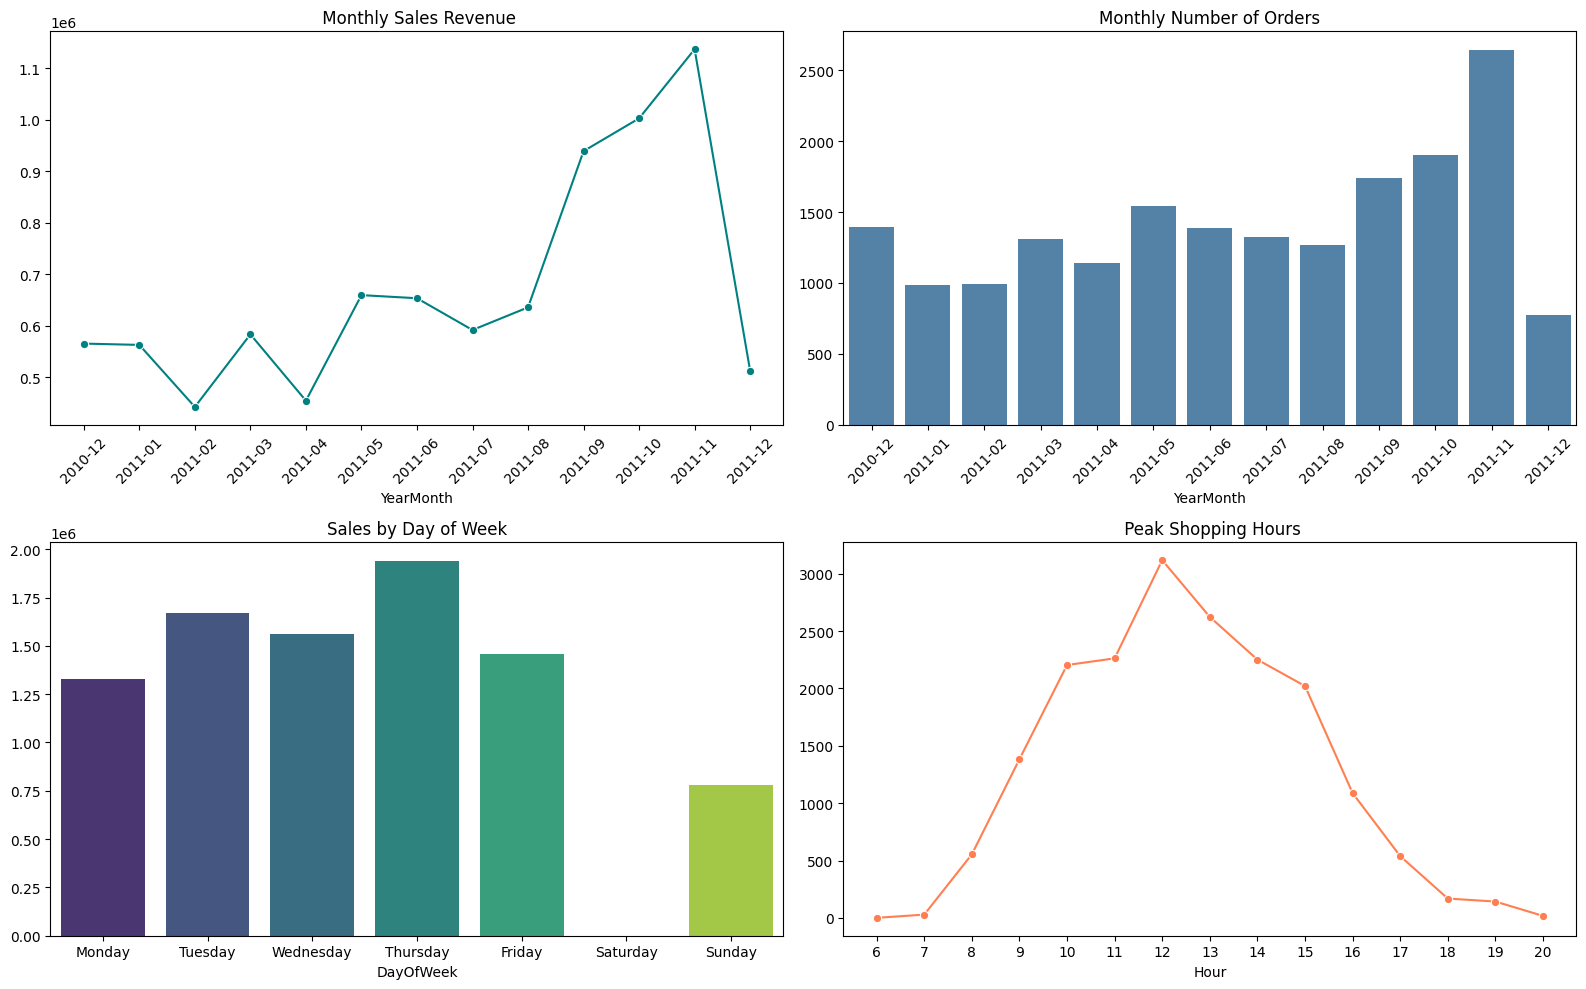

In [27]:
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M').astype(str)
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Monthly Sales Analysis
monthly_sales = df_clean.groupby('YearMonth')['TotalPrice'].sum()
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o', ax=axes[0, 0], color='teal')
axes[0, 0].set_title(' Monthly Sales Revenue')
axes[0, 0].tick_params(axis='x', rotation=45)

# Monthly Orders Analysis
monthly_orders = df_clean.groupby('YearMonth')['InvoiceNo'].nunique()
sns.barplot(x=monthly_orders.index, y=monthly_orders.values, ax=axes[0, 1], color='steelblue')
axes[0, 1].set_title('Monthly Number of Orders')
axes[0, 1].tick_params(axis='x', rotation=45)

#  Daily Sales Trends
daily_sales = df_clean.groupby('DayOfWeek')['TotalPrice'].sum().reindex(days_order).fillna(0)
sns.barplot(x=daily_sales.index, y=daily_sales.values, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Sales by Day of Week')

#  Peak Shopping Periods (Hourly)
hourly_orders = df_clean.groupby('Hour')['InvoiceNo'].nunique()
sns.lineplot(x=hourly_orders.index, y=hourly_orders.values, marker='o', ax=axes[1, 1], color='coral')
axes[1, 1].set_title(' Peak Shopping Hours')
axes[1, 1].set_xticks(range(6, 21))

plt.tight_layout()
plt.show()

Product Analysis

/tmp/ipykernel_855/1047447948.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_qty_products.values, y=top_qty_products.index, ax=axes[0], palette='Blues_r')
/tmp/ipykernel_855/1047447948.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_rev_products.values, y=top_rev_products.index, ax=axes[1], palette='Greens_r')


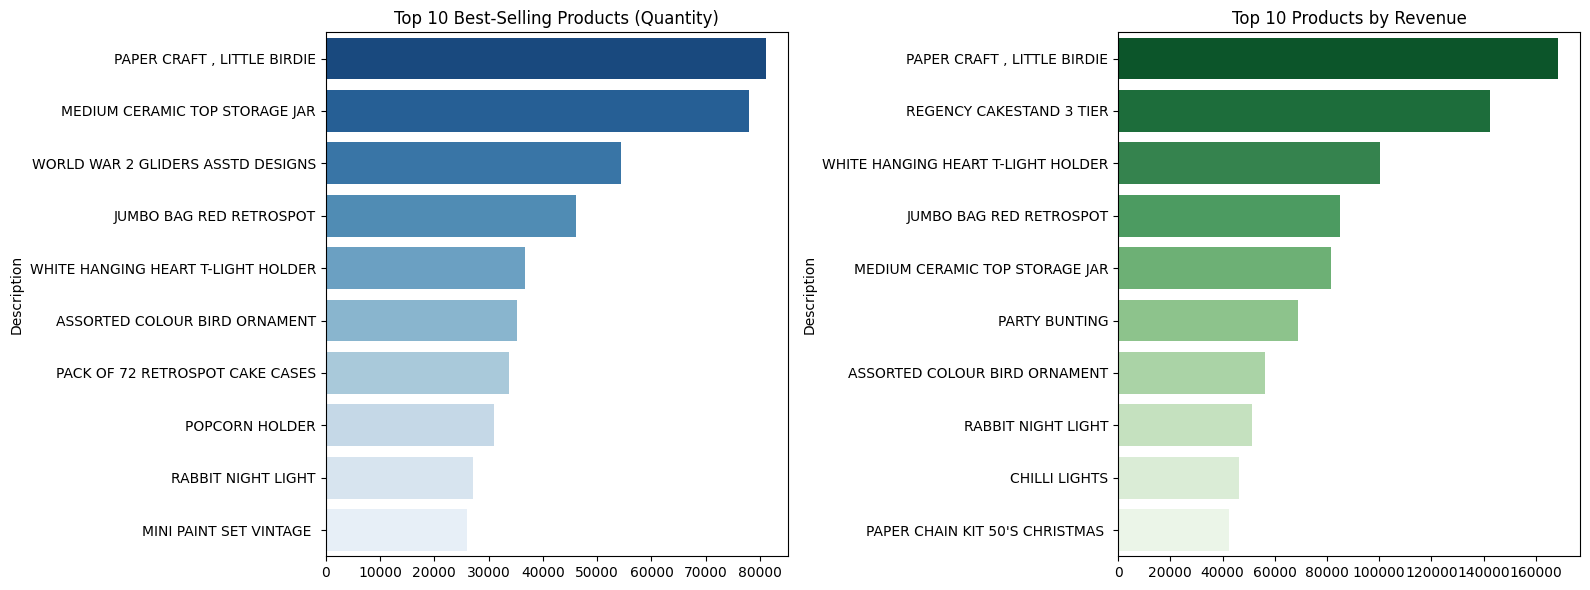

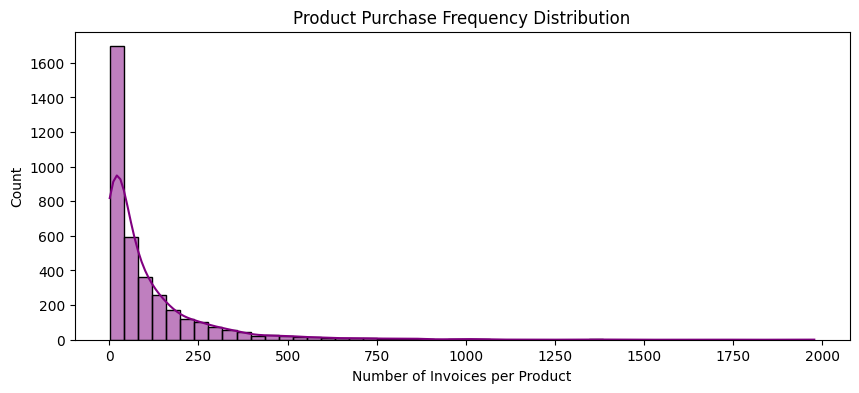

In [28]:
# Top 10 Best-Selling Products (by Quantity)
top_qty_products = df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

# Top 10 Products with Highest Revenue
top_rev_products = df_clean.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=top_qty_products.values, y=top_qty_products.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Best-Selling Products (Quantity)')

sns.barplot(x=top_rev_products.values, y=top_rev_products.index, ax=axes[1], palette='Greens_r')
axes[1].set_title('Top 10 Products by Revenue')

plt.tight_layout()
plt.show()

# Product Purchase Distribution
product_dist = df_clean.groupby('StockCode')['InvoiceNo'].nunique()
plt.figure(figsize=(10, 4))
sns.histplot(product_dist, bins=50, kde=True, color='purple')
plt.title('Product Purchase Frequency Distribution')
plt.xlabel('Number of Invoices per Product')
plt.show()

 Country Analysis

Top 10 Countries by Revenue & Customers:
                Unique_Customers  Total_Revenue
Country                                        
United Kingdom              3916    7242855.323
Netherlands                    9     283889.340
EIRE                           3     257013.120
Germany                       94     205381.150
France                        87     183801.940
Australia                      9     138103.810
Spain                         30      55706.560
Switzerland                   21      52441.950
Japan                          8      37416.370
Belgium                       25      36927.340


/tmp/ipykernel_855/338031295.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_countries['Total_Revenue'], y=top_10_countries.index, palette='magma')


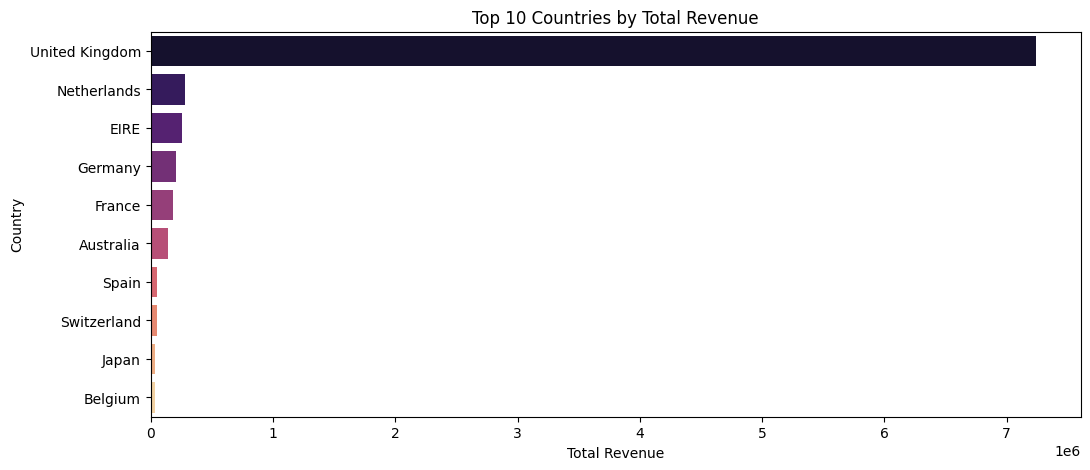

In [29]:
# Number of Customers & Revenue per Country
country_stats = df_clean.groupby('Country').agg(
    Unique_Customers=('CustomerID', 'nunique'),
    Total_Revenue=('TotalPrice', 'sum')
).sort_values(by='Total_Revenue', ascending=False)

print("Top 10 Countries by Revenue & Customers:")
print(country_stats.head(10))

# Top 10 Countries by Revenue Chart
top_10_countries = country_stats.head(10)
plt.figure(figsize=(12, 5))
sns.barplot(x=top_10_countries['Total_Revenue'], y=top_10_countries.index, palette='magma')
plt.title('Top 10 Countries by Total Revenue')
plt.xlabel('Total Revenue')
plt.show()

Customer Behavior Analysis

Average Spending per Customer: 2015.97
Median Spending per Customer: 662.57


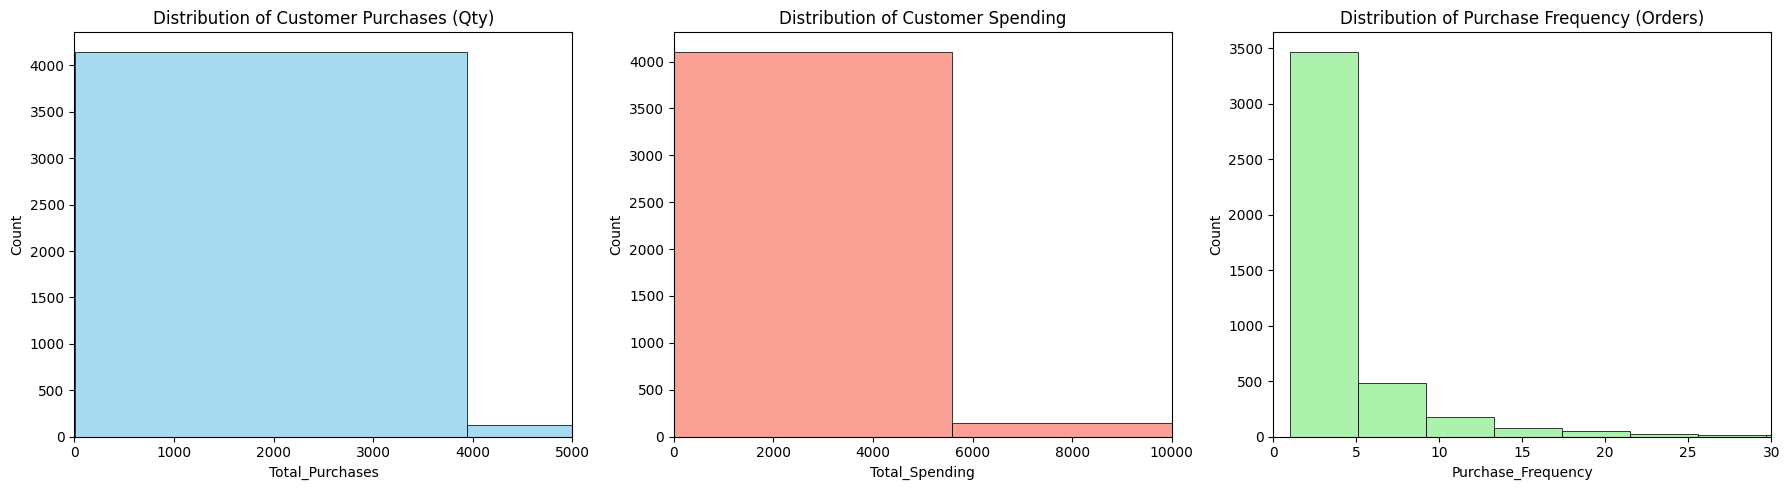

In [30]:
customer_behavior = df_clean.groupby('CustomerID').agg(
    Total_Purchases=('Quantity', 'sum'),
    Total_Spending=('TotalPrice', 'sum'),
    Purchase_Frequency=('InvoiceNo', 'nunique')
)

print("Average Spending per Customer:", round(customer_behavior['Total_Spending'].mean(), 2))
print("Median Spending per Customer:", round(customer_behavior['Total_Spending'].median(), 2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution of Customer Purchases
sns.histplot(customer_behavior['Total_Purchases'], bins=50, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Customer Purchases (Qty)')
axes[0].set_xlim(0, 5000)

# Distribution of Customer Spending
sns.histplot(customer_behavior['Total_Spending'], bins=50, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Customer Spending')
axes[1].set_xlim(0, 10000)

# Distribution of Purchase Frequency
sns.histplot(customer_behavior['Purchase_Frequency'], bins=50, ax=axes[2], color='lightgreen')
axes[2].set_title('Distribution of Purchase Frequency (Orders)')
axes[2].set_xlim(0, 30)

plt.tight_layout()
plt.show()

# **part3**     RFM Analysis & Feature Engineering

**Goal:** turn the transaction-level data (`df_clean`, one row per product line) into customer-level data (`rfm`, one row per customer), then prepare it for K-Means: explore, treat outliers, transform, and scale.


## 3.1) Introduction to RFM Analysis
**What is RFM?** A classic marketing technique that describes each customer with 3 numbers built from their purchase history:

| Feature | Question it answers | How we compute it | Good customer |
|---|---|---|---|
| **R**ecency | How recently did the customer buy? | days between the reference date and the customer's last purchase | **low** value |
| **F**requency | How often does the customer buy? | number of unique invoices | **high** value |
| **M**onetary | How much does the customer spend? | sum of `TotalPrice` | **high** value |

**Why RFM for Customer Segmentation?**
- It turns thousands of transaction rows into 3 behavioral features that are easy to interpret.
- K-Means needs one numeric row per customer, and RFM gives exactly that.
- Each cluster can be explained in business language (for example: high F + high M + low R = loyal, high-value customers), which is what the rule-based marketing recommendations in the next part need.

**Note:** we use `df_clean` only (no cancelled invoices, no non-product codes), so RFM measures real buying behavior.

## 3.2) Define Reference Date
**Why:** Recency is "days since the last purchase", so we need one fixed "today" for all customers. We cannot use the real current date, because the data ends in Dec 2011 and every Recency would be huge and meaningless.

**Decision:** reference date = the day after the last transaction in the data. This way the most recent customer has Recency = 1 (not 0).
**Result:** the last transaction is on 2011-12-09, so the reference date is **2011-12-10**.


In [31]:
last_date = df_clean["InvoiceDate"].max()
snapshot_date = last_date.normalize() + pd.Timedelta(days=1)

print("Last transaction in data :", last_date)
print("Reference (snapshot) date:", snapshot_date)

Last transaction in data : 2011-12-09 12:50:00
Reference (snapshot) date: 2011-12-10 00:00:00


## 3.3) Calculate RFM Features
We calculate each feature separately with `groupby("CustomerID")`, then combine them in 3.4.

### 3.3.1) Recency
**How:** last purchase date per customer, then the number of days between it and the reference date.
We use `normalize()` to drop the time of day, so Recency is counted in whole days.

In [32]:
last_purchase = df_clean.groupby("CustomerID")["InvoiceDate"].max().dt.normalize()
recency = (snapshot_date - last_purchase).dt.days.rename("Recency")

display(recency.head())
print("Min Recency:", recency.min(), "| Max Recency:", recency.max())

,Recency
CustomerID,
12346,326
12347,3
12348,76
12349,19
12350,311


Min Recency: 1 | Max Recency: 374


### 3.3.2) Frequency
**How:** number of **unique invoices** per customer (`nunique` on `InvoiceNo`).
**Why not count rows:** one invoice contains many product lines, so counting rows would measure basket size, not how often the customer comes back.

In [33]:
frequency = df_clean.groupby("CustomerID")["InvoiceNo"].nunique().rename("Frequency")

display(frequency.head())
print("Min Frequency:", frequency.min(), "| Max Frequency:", frequency.max())

,Frequency
CustomerID,
12346,1
12347,7
12348,4
12349,1
12350,1


Min Frequency: 1 | Max Frequency: 206


### 3.3.3) Monetary
**How:** sum of `TotalPrice` (created in Part 1) per customer.
Because cancellations and non-product codes were already removed, Monetary is the money the customer really spent on products.

In [34]:
monetary = df_clean.groupby("CustomerID")["TotalPrice"].sum().rename("Monetary")

display(monetary.head())
print("Min Monetary:", round(monetary.min(), 2), "| Max Monetary:", round(monetary.max(), 2))

,Monetary
CustomerID,
12346,77183.60
12347,4310.00
12348,1437.24
12349,1457.55
12350,294.40


Min Monetary: 3.75 | Max Monetary: 279138.02


## 3.4) Create RFM Table
Combine R, F and M into one table where **each row is one customer** (`CustomerID` is the index).
**Check:** the number of rows must equal the number of unique customers in `df_clean` (4,334), so no customer is lost or duplicated.

In [35]:
rfm = pd.concat([recency, frequency, monetary], axis=1)

display(rfm.head(10))
print("Shape                        :", rfm.shape)
print("Number of customers in RFM   :", rfm.shape[0])
print("Unique customers in df_clean :", df_clean["CustomerID"].nunique())

assert rfm.shape[0] == df_clean["CustomerID"].nunique()
assert rfm.index.is_unique

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,3,7,4310.00
12348,76,4,1437.24
12349,19,1,1457.55
12350,311,1,294.40
12352,37,7,1385.74
12353,205,1,89.00
12354,233,1,1079.40
12355,215,1,459.40


Shape                        : (4334, 3)
Number of customers in RFM   : 4334
Unique customers in df_clean : 4334


## 3.5) RFM Data Exploration
We look at the distribution of each feature, the summary statistics, and the skewness before touching the data.
**What to look for:** K-Means uses distances and is sensitive to scale and to skewed data, so we need to know how skewed R, F and M are.

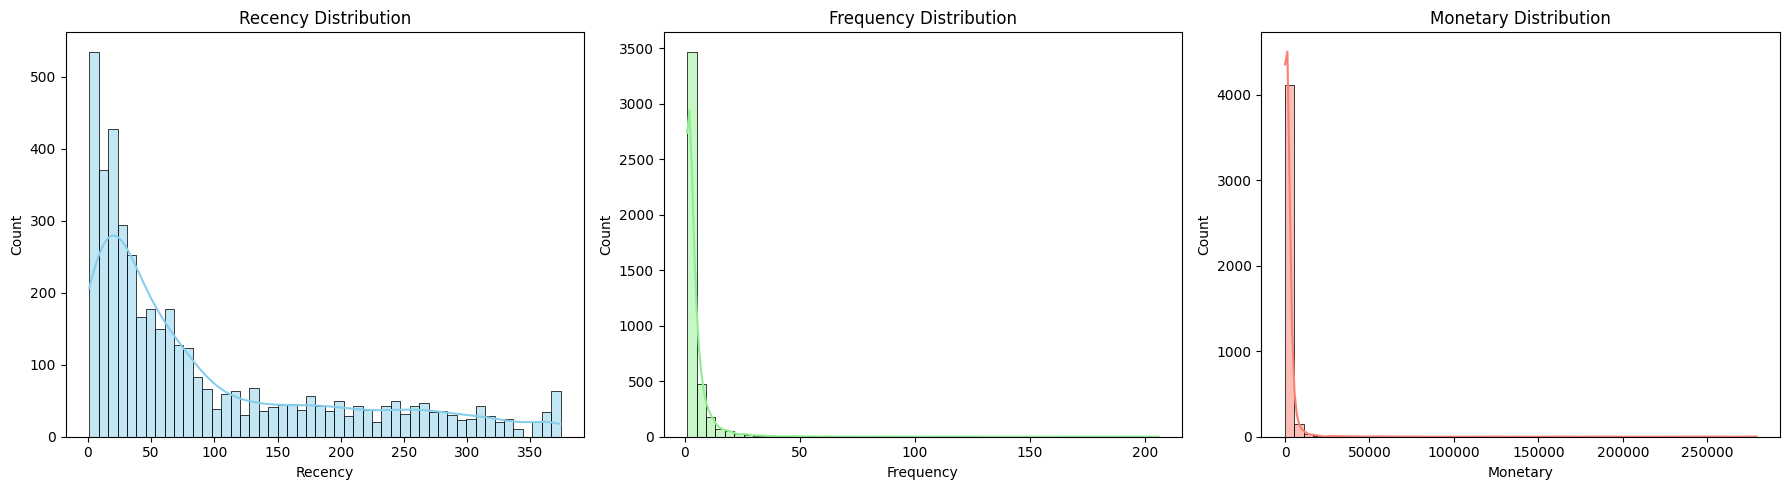

In [36]:
rfm_cols = ["Recency", "Frequency", "Monetary"]
colors = ["skyblue", "lightgreen", "salmon"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, color in zip(axes, rfm_cols, colors):
    sns.histplot(rfm[col], bins=50, kde=True, ax=ax, color=color)
    ax.set_title(f"{col} Distribution")
plt.tight_layout()
plt.show()

**Summary statistics:** compare the mean with the median (50%) and with the max. A mean far above the median means a long right tail.

In [37]:
display(rfm.describe().round(2))

comparison = pd.DataFrame({"Mean": rfm.mean(), "Median": rfm.median()}).round(2)
comparison["Mean / Median"] = (comparison["Mean"] / comparison["Median"]).round(2)
display(comparison)

,Recency,Frequency,Monetary
count,4334.00,4334.00,4334.00
mean,93.23,4.25,2015.97
std,100.18,7.63,8903.67
min,1.00,1.00,3.75
25%,18.00,1.00,304.24
50%,51.00,2.00,662.56
75%,143.00,5.00,1631.62
max,374.00,206.00,279138.02


,Mean,Median,Mean / Median
Recency,93.23,51.00,1.83
Frequency,4.25,2.00,2.12
Monetary,2015.97,662.56,3.04


**Skewness analysis:** skewness measures how asymmetric a distribution is.
- close to 0: symmetric
- between 0.5 and 1: moderately skewed
- above 1: highly right-skewed (long tail of very large values)

In [38]:
skew_before = rfm.skew().round(2)
print("Skewness before transformation:")
print(skew_before)

Skewness before transformation:
Recency       1.24
Frequency    11.95
Monetary     19.58
dtype: float64


**Result:** Frequency and Monetary are strongly right-skewed (most customers buy a little, a few buy a lot), and Recency is also right-skewed. These are the expected shapes for retail data, and they are the reason for the outlier treatment and the log transformation in the next steps.

## 3.6) Outlier Detection & Treatment
We detect outliers with **boxplots** first (visual), then with the **IQR method** (numeric), then decide what to do.

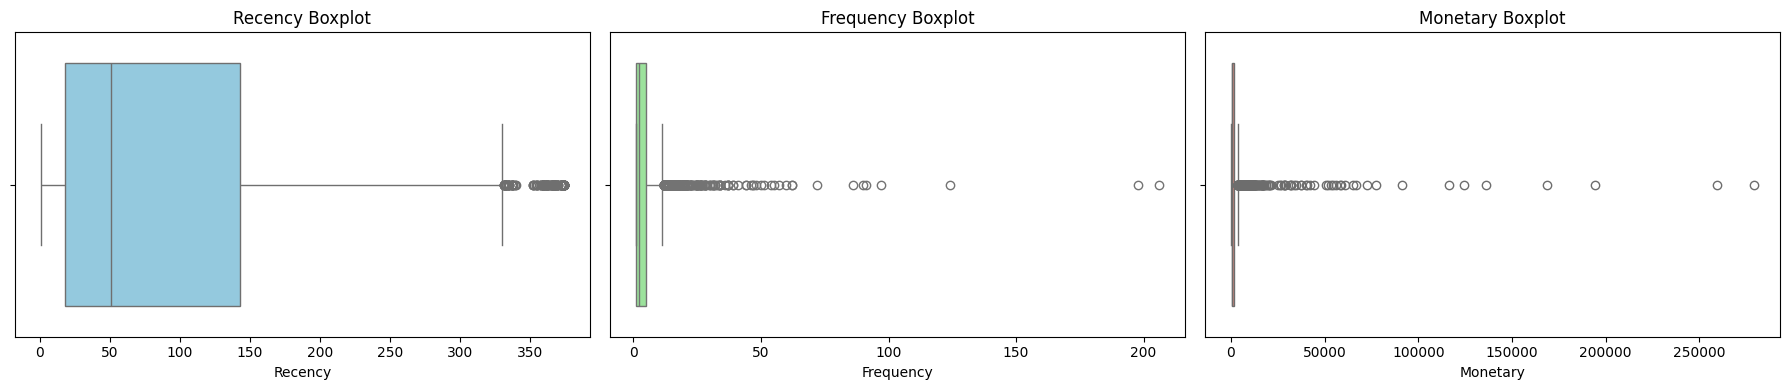

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col, color in zip(axes, rfm_cols, colors):
    sns.boxplot(x=rfm[col], ax=ax, color=color)
    ax.set_title(f"{col} Boxplot")
plt.tight_layout()
plt.show()

**IQR method:** `IQR = Q3 - Q1`. A value is an outlier if it is below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

In [40]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in rfm_cols:
    low, high = iqr_bounds(rfm[col])
    n_out = ((rfm[col] < low) | (rfm[col] > high)).sum()
    rows.append({"Feature": col,
                 "Lower bound": round(low, 2),
                 "Upper bound": round(high, 2),
                 "Outliers": n_out,
                 "% of customers": round(n_out / len(rfm) * 100, 2)})

outlier_summary = pd.DataFrame(rows).set_index("Feature")
display(outlier_summary)

,Lower bound,Upper bound,Outliers,% of customers
Feature,,,,
Recency,-169.50,330.5,153,3.53
Frequency,-5.00,11.0,278,6.41
Monetary,-1686.83,3622.7,421,9.71


**Before deciding:** how much of the business do these outliers represent? If they are a tiny group that carries a big share of the revenue, deleting them would remove our best customers.

In [41]:
is_outlier = pd.Series(False, index=rfm.index)
for col in rfm_cols:
    low, high = iqr_bounds(rfm[col])
    is_outlier |= (rfm[col] < low) | (rfm[col] > high)

revenue_share = rfm.loc[is_outlier, "Monetary"].sum() / rfm["Monetary"].sum()

print(f"Customers flagged in at least one feature: {is_outlier.sum():,} ({is_outlier.mean():.1%})")
print(f"Their share of total revenue             : {revenue_share:.1%}")

Customers flagged in at least one feature: 620 (14.3%)
Their share of total revenue             : 62.9%


**Decision:** we **keep** the outliers (no removal, no capping).
**Why:**
- They are not errors. Cancellations, zero prices and non-product codes were already cleaned in Part 1, so these are real wholesale and loyal customers.
- Together they carry a large share of the revenue, and they are exactly the "VIP / Champions" group the project wants to find.
- Removing them would leave the best customers without any marketing strategy.

**How we handle them instead:** the log transformation in 3.7 pulls the extreme values in and reduces their pull on the K-Means centroids, without deleting any customer.

## 3.7) Feature Transformation
**Why:** K-Means uses Euclidean distance, so a few huge values (very large Monetary or Frequency) would dominate the distance and the centroids. A log transformation compresses the long right tail and makes the distribution closer to symmetric.

**Rule:** apply `np.log1p` (that is `log(1 + x)`, safe even when a value is 0) only to the features whose skewness is above 1. The transformed columns get a `_log` suffix.

In [42]:
skew_threshold = 1
skewed_cols = [col for col in rfm_cols if abs(rfm[col].skew()) > skew_threshold]
print("Features to transform:", skewed_cols)

rfm_log = rfm.copy()
for col in skewed_cols:
    rfm_log[col] = np.log1p(rfm_log[col])

rfm_log = rfm_log.rename(columns={col: f"{col}_log" for col in skewed_cols})
display(rfm_log.head())

Features to transform: ['Recency', 'Frequency', 'Monetary']


,Recency_log,Frequency_log,Monetary_log
CustomerID,,,
12346,5.789960,0.693147,11.253955
12347,1.386294,2.079442,8.368925
12348,4.343805,1.609438,7.271175
12349,2.995732,0.693147,7.285198
12350,5.743003,0.693147,5.688330


**Compare distributions before and after:** top row is the original data, bottom row is after the transformation.

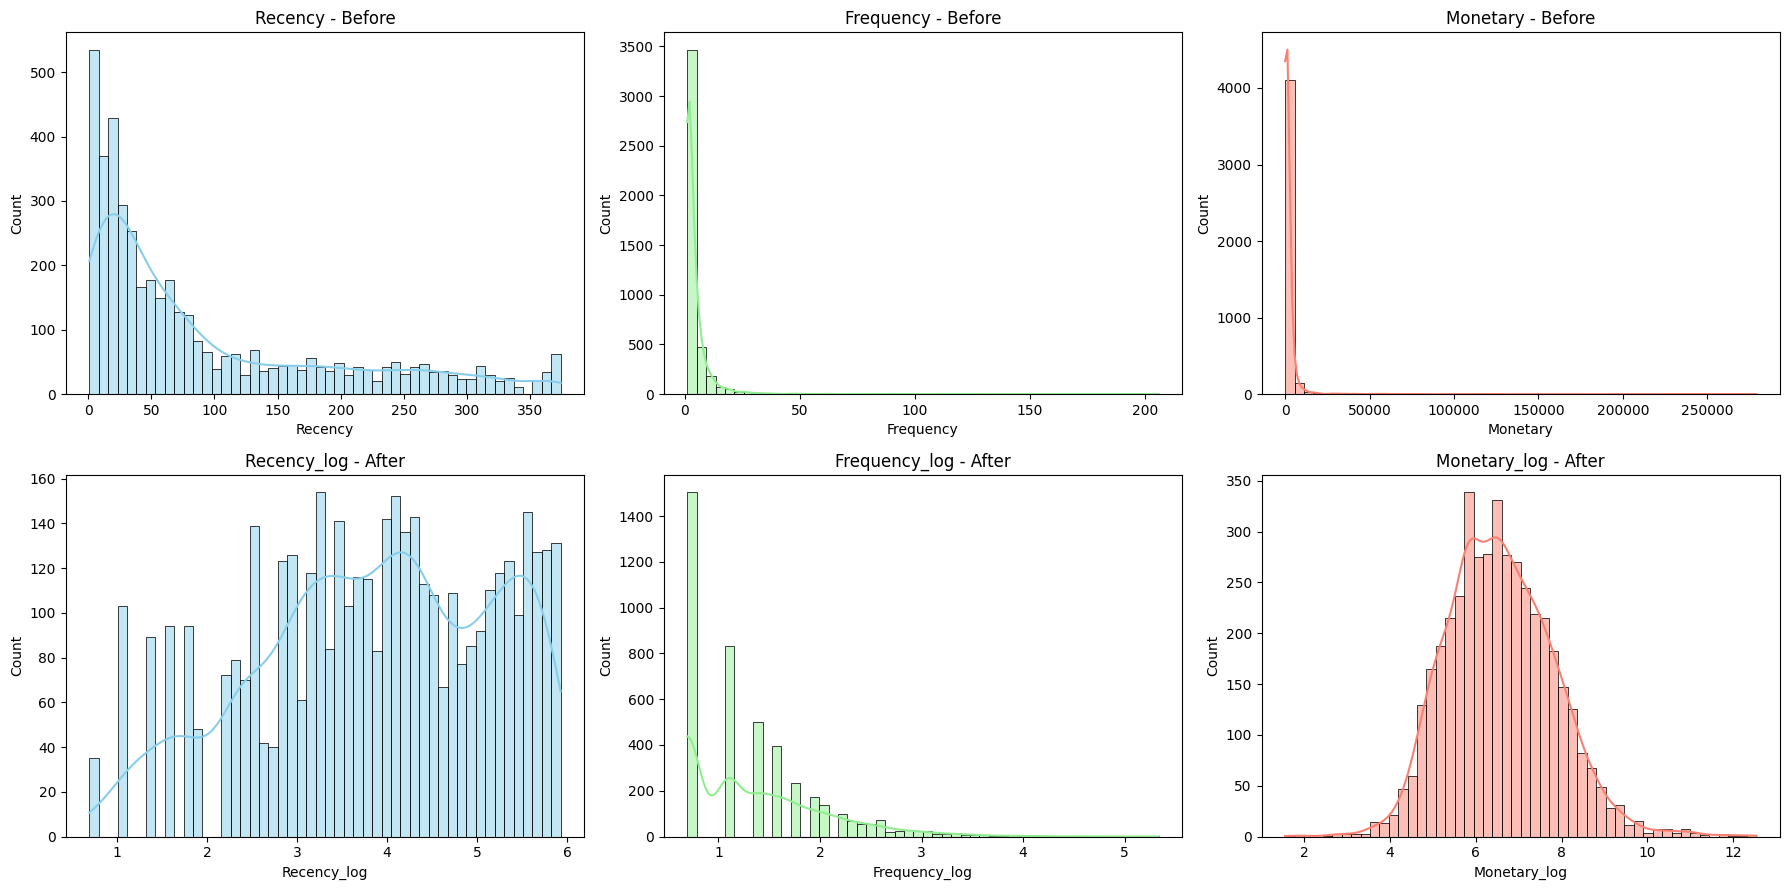

,Before,After
Recency,1.24,-0.33
Frequency,11.95,1.21
Monetary,19.58,0.40


In [43]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for i, (col, color) in enumerate(zip(rfm_cols, colors)):
    sns.histplot(rfm[col], bins=50, kde=True, ax=axes[0, i], color=color)
    axes[0, i].set_title(f"{col} - Before")

    new_col = rfm_log.columns[i]
    sns.histplot(rfm_log[new_col], bins=50, kde=True, ax=axes[1, i], color=color)
    axes[1, i].set_title(f"{new_col} - After")

plt.tight_layout()
plt.show()

skew_compare = pd.DataFrame({"Before": rfm.skew().values,
                             "After": rfm_log.skew().values},
                            index=rfm_cols).round(2)
display(skew_compare)

**Result:** the skewness of the transformed features drops sharply and the histograms become much more bell-shaped. The data is now much better suited to K-Means.

## 3.8) Feature Scaling
**Why:** R is measured in days, F in number of invoices, and M in currency, so they are on very different scales. Without scaling, the feature with the biggest numbers would control the distance in K-Means.

**How:** `StandardScaler` transforms each feature to `z = (x - mean) / std`, so every feature ends with mean 0 and standard deviation 1.
We fit the scaler on the log-transformed data and keep the original `rfm` (unscaled) for profiling the clusters later.

In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_array = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(scaled_array,
                          columns=[f"{col}_scaled" for col in rfm_log.columns],
                          index=rfm_log.index)

display(rfm_scaled.head())

,Recency_log_scaled,Frequency_log_scaled,Monetary_log_scaled
CustomerID,,,
12346,1.477298,-0.951280,3.728238
12347,-1.890934,1.082291,1.429174
12348,0.371177,0.392837,0.554384
12349,-0.659923,-0.951280,0.565558
12350,1.441382,-0.951280,-0.706976


## 3.9) Final Feature Validation
Before clustering we check the scaled dataset: mean ≈ 0, standard deviation ≈ 1, the expected shape, and no missing or infinite values.

In [45]:
print("Mean of each feature:")
print(rfm_scaled.mean().round(6))
print("\nStd of each feature:")
print(rfm_scaled.std(ddof=0).round(6))

print("\nShape             :", rfm_scaled.shape)
print("Missing values    :", rfm_scaled.isnull().sum().sum())
print("Infinite values   :", np.isinf(rfm_scaled).sum().sum())
print("Same customers as rfm:", rfm_scaled.index.equals(rfm.index))

assert np.allclose(rfm_scaled.mean(), 0, atol=1e-8)
assert np.allclose(rfm_scaled.std(ddof=0), 1)
assert rfm_scaled.shape == (rfm.shape[0], 3)
assert rfm_scaled.isnull().sum().sum() == 0
assert rfm_scaled.index.equals(rfm.index)

Mean of each feature:
Recency_log_scaled     -0.0
Frequency_log_scaled   -0.0
Monetary_log_scaled    -0.0
dtype: float64

Std of each feature:
Recency_log_scaled      1.0
Frequency_log_scaled    1.0
Monetary_log_scaled     1.0
dtype: float64

Shape             : (4334, 3)
Missing values    : 0
Infinite values   : 0
Same customers as rfm: True


**Note:** we use `ddof=0` because `StandardScaler` divides by the population standard deviation. With pandas' default (`ddof=1`) the std would show 1.0001 instead of exactly 1.

## 3.10) Save Processed RFM Dataset
We save three files plus the scaler:
- `rfm_table.csv`: original RFM values (used to profile and explain the clusters in business units)
- `rfm_log.csv`: log-transformed RFM
- `rfm_scaled.csv`: the final input for K-Means
- `rfm_scaler.pkl`: the fitted scaler, so a new customer can be scaled in the same way later (for example in the Streamlit dashboard)

`CustomerID` is the index here, so we save with the index (unlike Part 1, where `index=False`).

In [46]:
import joblib

rfm.to_csv("rfm_table.csv")
rfm_log.to_csv("rfm_log.csv")
rfm_scaled.to_csv("rfm_scaled.csv")
joblib.dump(scaler, "rfm_scaler.pkl")

print("Saved: rfm_table.csv, rfm_log.csv, rfm_scaled.csv, rfm_scaler.pkl")

Saved: rfm_table.csv, rfm_log.csv, rfm_scaled.csv, rfm_scaler.pkl


### Part 3 Result

We converted `df_clean` (391,153 transaction rows) into `rfm`, a customer-level table with **4,334 customers** and 3 features: Recency, Frequency and Monetary.

- Reference date: 2011-12-10 (the day after the last transaction).
- Outliers were detected with boxplots and the IQR method and **kept**, because they are real high-value customers.
- Skewed features were log-transformed (`log1p`), then standardized with `StandardScaler`.
- The final dataset `rfm_scaled` has no missing values, mean ≈ 0 and std ≈ 1, and is ready for K-Means.